# 05 — Despliegue y Visualización
**Criterio 3.1.5.I.5 (25%):** Dashboard funcional con KPIs, jerarquía, filtros y trazabilidad.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.1f}".format)

BASE = Path("../01_datos/procesados")
COLS = ["TipoCompra","codigoOC","Anio","Mes","MontoNetoItemCLP",
        "Region","Servicio","Subtitulo","ProveedorRUT","CodBIP","NombreProyecto","Proy_Gasto_MM"]

print("Cargando datos...")
it  = pd.read_csv(BASE / "compras_presupuesto_items.csv", sep=";", low_memory=False, usecols=COLS)
res = pd.read_csv(BASE / "compras_presupuesto_resumen.csv", sep=";", encoding="utf-8-sig")
pres= pd.read_csv(BASE / "presupuesto_2018_2019_unificado.csv", sep=";", encoding="utf-8-sig")

it  = it[it["MontoNetoItemCLP"] > 0].copy()
it["MM"] = it["MontoNetoItemCLP"] / 1e6
it["Trimestre"] = ((it["Mes"]-1)//3+1).map({1:"Q1",2:"Q2",3:"Q3",4:"Q4"})
it["EsInversion"] = (it["Subtitulo"].fillna(-1).astype(int) == 31).astype(int)
it["TieneBIP"] = it["CodBIP"].notna().astype(int)

print(f"Items  : {len(it):,} filas")
print(f"Resumen: {len(res):,} filas")
print(f"Presup.: {len(pres):,} filas")

Cargando datos...
Items  : 172,310 filas
Resumen: 357 filas
Presup.: 3,179 filas


## 5.1 Panel de KPIs Ejecutivos

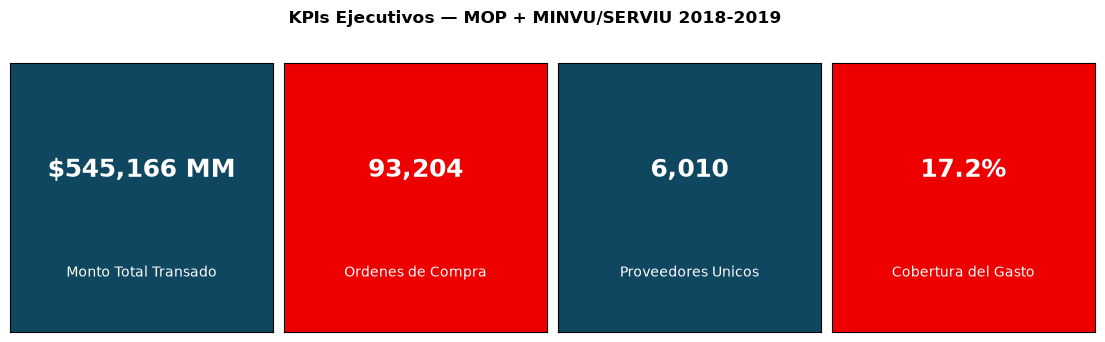

In [2]:
import matplotlib.gridspec as gridspec

anual = res.groupby("Anio")[["RS_Gasto_MM","Compras_MM"]].sum()
tot_MM = it["MM"].sum()
n_oc   = it["codigoOC"].nunique()
n_prov = it["ProveedorRUT"].nunique()
cob    = 100*tot_MM/anual.RS_Gasto_MM.sum()

kpis_vals = [
    (f"${tot_MM:,.0f} MM", "Monto Total Transado"),
    (f"{n_oc:,}",          "Ordenes de Compra"),
    (f"{n_prov:,}",        "Proveedores Unicos"),
    (f"{cob:.1f}%",        "Cobertura del Gasto"),
]
colors = ["#0F4761","#EE0000","#0F4761","#EE0000"]

fig = plt.figure(figsize=(14,3.5))
gs  = gridspec.GridSpec(1,4,figure=fig,wspace=0.04)
for i,(val,lab) in enumerate(kpis_vals):
    ax = fig.add_subplot(gs[0,i])
    ax.set_facecolor(colors[i])
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.text(0.5,0.6,val,ha="center",va="center",fontsize=18,fontweight="bold",
            color="white",transform=ax.transAxes)
    ax.text(0.5,0.22,lab,ha="center",va="center",fontsize=10,
            color="white",transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("KPIs Ejecutivos — MOP + MINVU/SERVIU 2018-2019",fontsize=12,fontweight="bold",y=1.03)
plt.savefig("../05_figuras/nb05_fig1_kpis.png",dpi=130,bbox_inches="tight")
plt.show()

## 5.2 Heatmap: Monto por Región × Mes

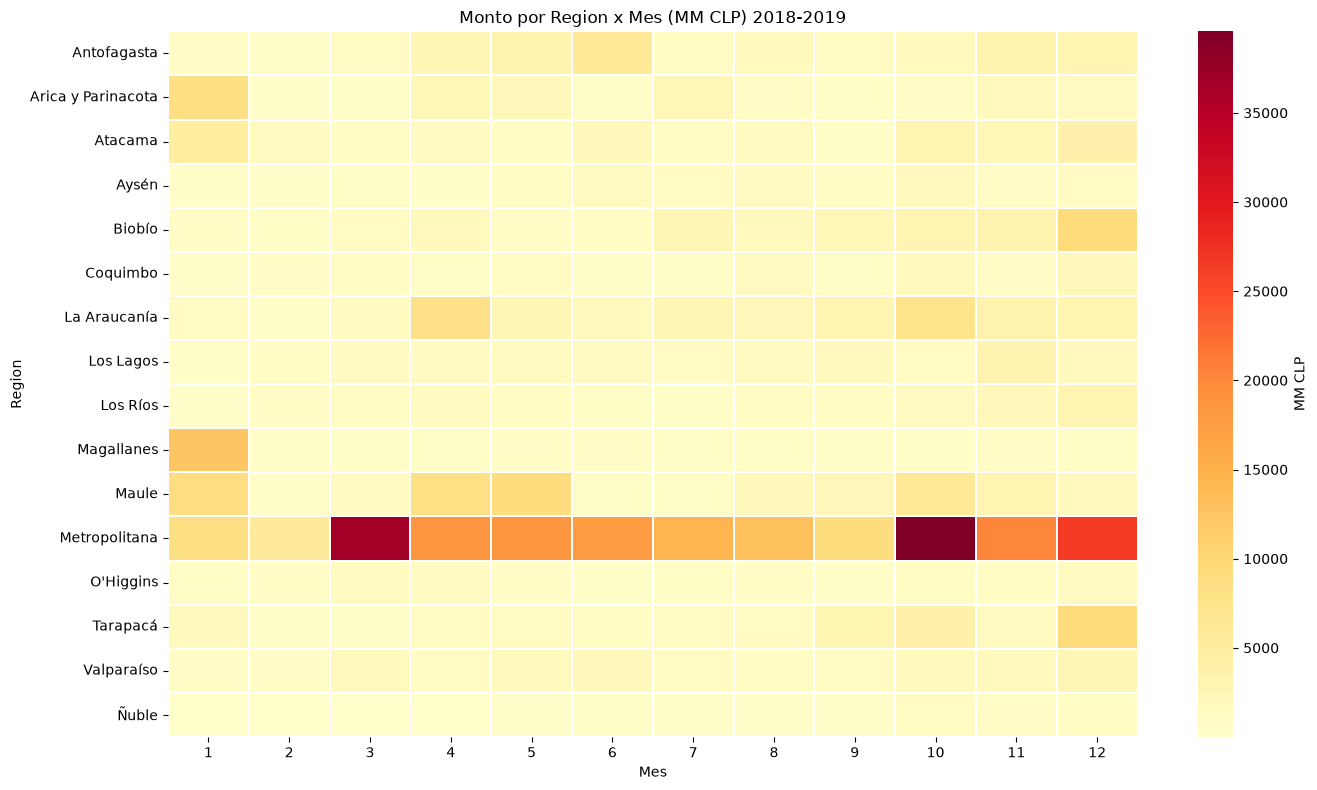

In [3]:
pivot = it.groupby(["Region","Mes"]).MM.sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(14,8))
sns.heatmap(pivot, cmap="YlOrRd", annot=False, linewidths=0.3,
            ax=ax, cbar_kws={"label":"MM CLP"})
ax.set_title("Monto por Region x Mes (MM CLP) 2018-2019")
ax.set_xlabel("Mes"); ax.set_ylabel("Region")
plt.tight_layout()
plt.savefig("../05_figuras/nb05_fig2_heatmap.png",dpi=120,bbox_inches="tight")
plt.show()

## 5.3 Comparativo 2018 vs 2019 por Servicio

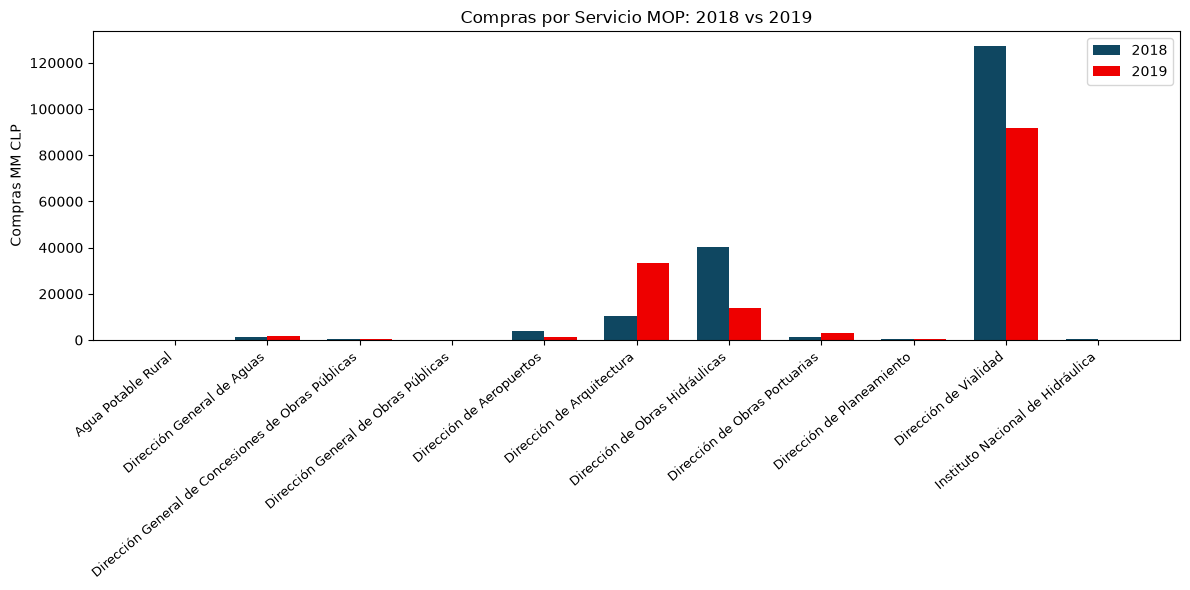

In [4]:
serv = (res[~res.Servicio.str.startswith(("MINVU","MOP otros"))]
         .groupby(["Servicio","Anio"]).Compras_MM.sum().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(12,6))
x = np.arange(len(serv)); w = 0.35
ax.bar(x-w/2, serv.get(2018,0), w, label="2018", color="#0F4761")
ax.bar(x+w/2, serv.get(2019,0), w, label="2019", color="#EE0000")
ax.set_xticks(x); ax.set_xticklabels(serv.index, rotation=40, ha="right", fontsize=9)
ax.set_ylabel("Compras MM CLP")
ax.set_title("Compras por Servicio MOP: 2018 vs 2019")
ax.legend(); plt.tight_layout()
plt.savefig("../05_figuras/nb05_fig3_servicios.png",dpi=120,bbox_inches="tight")
plt.show()

## 5.4 Despliegue y Ejecución Automática del Dashboard Streamlit


In [2]:
# ==============================================================================
# DASHBOARD INTERACTIVO (STREAMLIT)
# ==============================================================================
# Para ejecutar manualmente desde la terminal (opcional):
#   1. Abrir terminal en la carpeta 'entrega final/'
#   2. Ejecutar: streamlit run 04_dashboard/dashboard_app.py
#   3. Abrir: http://localhost:8501
# Funcionalidades: filtros Año/Región/Modalidad, KPIs, gráficos y tabla proveedores.
# ==============================================================================

import subprocess
import sys
import webbrowser
import time
import socket
from pathlib import Path

# Localizar archivo del dashboard de forma robusta
posibles_rutas = [
    Path("../04_dashboard/dashboard_app.py"),
    Path("04_dashboard/dashboard_app.py"),
    Path("entrega final/04_dashboard/dashboard_app.py"),
    Path.cwd().parent / "04_dashboard" / "dashboard_app.py",
]

ruta_dashboard = None
for p in posibles_rutas:
    if p.resolve().exists():
        ruta_dashboard = p.resolve()
        break

if not ruta_dashboard:
    raise FileNotFoundError("No se encontró el archivo dashboard_app.py en las rutas esperadas.")

# Comprobar si el puerto 8501 ya está en uso
def puerto_activo(puerto=8501):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        return s.connect_ex(("localhost", puerto)) == 0

url = "http://localhost:8501"

if puerto_activo(8501):
    print("ℹ️ El Dashboard de Streamlit ya se encuentra en ejecución.")
    print(f"🌐 Abriendo en navegador: {url}")
    webbrowser.open(url)
else:
    print("🚀 Iniciando Dashboard de Streamlit en segundo plano...")
    subprocess.Popen([sys.executable, "-m", "streamlit", "run", str(ruta_dashboard)])
    time.sleep(2)
    webbrowser.open(url)
    print(f"✅ Dashboard iniciado y abierto automáticamente en: {url}")


🚀 Iniciando Dashboard de Streamlit en segundo plano...
✅ Dashboard iniciado y abierto automáticamente en: http://localhost:8501
